# Frames, camera intrinsics and grasp segmentation

The small building blocks every other part of the pipeline relies on. No GPU or simulator needed.

- `hurobo.utils.transforms`: `T_parent_child` helpers and the OpenCV-to-MuJoCo camera convention
- `hurobo.camera`: `CameraIntrinsics`, `ChArUcoCalibrator` (the printable board)
- `hurobo.demo`: `GraspSegmenter` (pinch aperture to grasp/release events)

Everything is synthetic here; real calibration is `scripts/01_calibrate_camera.py`.

In [ ]:
%load_ext autoreload
%autoreload 2

In [1]:
from hurobo.utils.notebook import setup_notebook

ROOT = setup_notebook()  # chdir to the repo root and set MUJOCO_GL=egl; must precede any mujoco import

## Frame conventions
A camera 0.5 m above the table looking at the table origin, in OpenCV convention (+z forward, +y down) and the MuJoCo equivalent (-z forward, +y up). Same origin; only the local axes differ.

In [2]:
import numpy as np

from hurobo.utils.transforms import (
    compose_transforms,
    cv_camera_pose_to_mujoco,
    invert_transform,
    look_at_origin_pose,
)
from hurobo.utils.viewer import frames_figure

T_table_cam_cv = look_at_origin_pose(np.array([0.4, -0.3, 0.5]))  # OpenCV axes: z forward, y down
T_table_cam_mj = cv_camera_pose_to_mujoco(T_table_cam_cv)

frames_figure(
    {"table": np.eye(4), "camera (OpenCV)": T_table_cam_cv},
    title="T_table_cam in OpenCV convention (camera z points at the table origin)",
).show()

# Round trip: inverting T_table_cam and composing recovers the identity.
assert np.allclose(compose_transforms(T_table_cam_cv, invert_transform(T_table_cam_cv)), np.eye(4))
print("mujoco camera z axis in table frame:", T_table_cam_mj[:3, 2].round(3), "(opposite of OpenCV z)")

mujoco camera z axis in table frame: [ 0.566 -0.424  0.707] (opposite of OpenCV z)


## Intrinsics: from a phone's field of view to a MuJoCo camera
MuJoCo cameras take one vertical FOV, so `CameraIntrinsics.fovy_degrees` is what `SceneTwin` uses.

In [3]:
from hurobo.camera import CameraIntrinsics

intrinsics = CameraIntrinsics.pinhole(image_width=1920, image_height=1080, fy=1500.0)
print(f"fx={intrinsics.fx:.0f}px  fy={intrinsics.fy:.0f}px  -> fovy={intrinsics.fovy_degrees:.1f} deg")

fx=1500px  fy=1500px  -> fovy=39.6 deg


## The calibration board
The board `scripts/01_calibrate_camera.py` asks you to print (and use as the table origin for the scan).

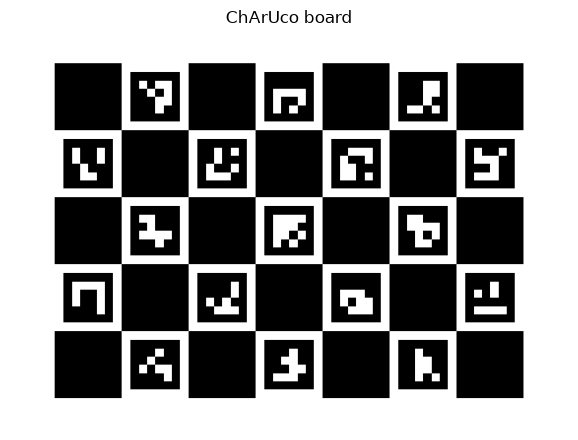

In [4]:
from hurobo.camera import ChArUcoCalibrator
from hurobo.utils.plotting import plot_image_row

board_image = ChArUcoCalibrator().generate_board_image(pixels_per_square=100)
plot_image_row({"ChArUco board": board_image}, height_in=4.5, cmap="gray")

## Markers on a tablet instead of a printer
`render_screen_marker_sheet` lays the table (10 cm), bowl and plate (5 cm) markers out at true physical size for a given display PPI (Surface Go 1: 217). A tablet lying on the table raises the marker plane by its thickness (8.3 mm); `--marker-height-m` on `scripts/13_teleop.py` corrects the absolute height for that (only used with `--table-height`; x/y are unaffected).

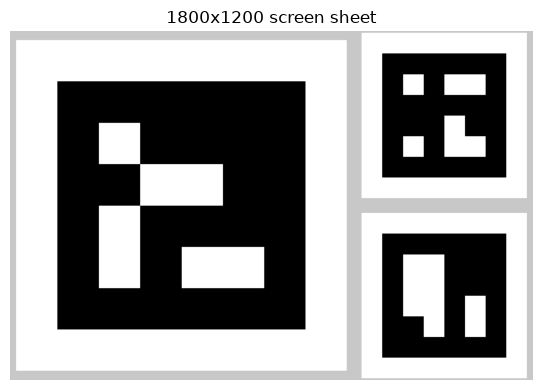

In [5]:
from hurobo.markers import MarkerLayout, render_screen_marker_sheet
from hurobo.utils.plotting import plot_image_row

layout = MarkerLayout(20, 0.10, {"bowl": 21, "plate": 22}, 0.05)
sheet = render_screen_marker_sheet(layout, ppi=217.0, screen_px=(1800, 1200))
plot_image_row({"1800x1200 screen sheet": sheet[..., ::-1]}, height_in=4.0)

## Grasp segmentation
Hysteresis on pinch aperture: closes below 3 cm, opens above 5 cm, so noise near one threshold does not flicker. Synthetic aperture below, with noise.

In [6]:
from hurobo.demo import GraspSegmenter
from hurobo.utils.synthetic import synthetic_aperture_trace
from hurobo.utils.viewer import aperture_figure

t, aperture = synthetic_aperture_trace()
is_grasping = GraspSegmenter(close_threshold_m=0.03, open_threshold_m=0.05).segment(aperture)
grasp_idx, release_idx = GraspSegmenter.find_transition_frames(is_grasping)
aperture_figure(t, aperture, 0.03, 0.05, grasp_idx, release_idx, "Synthetic pinch aperture").show()